# 03 – Train LSTM (Next-Note Prediction)
**Project**: MIDI Music Generation  
**Author**: [S33mi](https://github.com/S33mi/)

Train a small LSTM to predict the next note `(pitch, step, duration)`  
from a sequence of previous notes (output of notebook 02).

Expects under `data/processed/`:
- `X_train.npy`, `y_train.npy`, `X_val.npy`, `y_val.npy`
- `preprocess_config.pkl`

## 1. Setup & Imports

In [ ]:
import os
import pickle

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
GPU available: True


## 2. Load Preprocessed Data

In [ ]:
PROC = "data/processed"

X_train = np.load(os.path.join(PROC, "X_train.npy"))
y_train = np.load(os.path.join(PROC, "y_train.npy"))
X_val   = np.load(os.path.join(PROC, "X_val.npy"))
y_val   = np.load(os.path.join(PROC, "y_val.npy"))

with open(os.path.join(PROC, "preprocess_config.pkl"), "rb") as f:
    config = pickle.load(f)

SEQ_LENGTH = config["seq_length"]
FEATURE_NAMES = config["feature_names"]
step_mean, step_std = config["step_mean"], config["step_std"]
dur_mean, dur_std   = config["dur_mean"], config["dur_std"]

print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}  y_val  : {y_val.shape}")
print(f"Config : seq_length={SEQ_LENGTH}, features={FEATURE_NAMES}")

# Optional: subsample for faster Colab experiments
MAX_TRAIN = 200_000
if len(X_train) > MAX_TRAIN:
    idx = np.random.default_rng(42).choice(len(X_train), MAX_TRAIN, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]
    print(f"Subsampled train → {X_train.shape}")

X_train: (6004414, 32, 3)  y_train: (6004414, 3)
X_val  : (1059603, 32, 3)  y_val  : (1059603, 3)
Config : seq_length=32, features=['pitch', 'step', 'duration']
Subsampled train → (200000, 32, 3)


## 3. Model Architecture

Input: `(batch, seq_length, 3)` → LSTM stack → Dense head predicting  
next `[pitch, step, duration]`.

Pitch is treated as continuous (MIDI number) for a simple MSE setup.  
Step & duration are already z-scored from notebook 02.

In [ ]:
def build_model(seq_length=SEQ_LENGTH, n_features=3, lstm_units=128, dropout=0.2):
    inputs = keras.Input(shape=(seq_length, n_features), name="note_sequence")

    x = layers.LSTM(lstm_units, return_sequences=True)(inputs)
    x = layers.Dropout(dropout)(x)
    x = layers.LSTM(lstm_units)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x)

    # Single head: [pitch, step, duration]
    outputs = layers.Dense(n_features, name="next_note")(x)

    model = keras.Model(inputs, outputs, name="midi_lstm")
    return model

model = build_model()
model.summary()

Model: "midi_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ note_sequence (InputLayer)      │ (None, 32, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32, 128)        │        67,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_note (Dense)               │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 207,619 (811.01 KB)

 Trainable params: 207,619 (811.01 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Loss & Metrics

We use MSE on all three features.  
Optionally weight pitch a bit higher so melody is emphasized.


In [ ]:
def weighted_mse(y_true, y_pred):
    """Slightly higher weight on pitch (index 0)."""
    weights = tf.constant([1.5, 1.0, 1.0], dtype=tf.float32)
    err = tf.square(y_true - y_pred)
    return tf.reduce_mean(err * weights)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=weighted_mse,
    metrics=["mae"],
)

## 5. Callbacks

In [ ]:
os.makedirs("models", exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "models/lstm_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 6. Train


In [ ]:
BATCH_SIZE = 64
EPOCHS = 5                # 40          # raise if you have time / GPU

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/5
3124/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 200.6339 - mae: 5.1790
Epoch 1: val_loss improved from None to 71.80260, saving model to models/lstm_best.keras

Epoch 1: finished saving model to models/lstm_best.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 114s 35ms/step - loss: 104.1197 - mae: 4.0894 - val_loss: 71.8026 - val_mae: 3.5744 - learning_rate: 0.0010
Epoch 2/5
3123/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 76.5105 - mae: 3.6786
Epoch 2: val_loss improved from 71.80260 to 71.16566, saving model to models/lstm_best.keras

Epoch 2: finished saving model to models/lstm_best.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 102s 33ms/step - loss: 75.8711 - mae: 3.6618 - val_loss: 71.1657 - val_mae: 3.5832 - learning_rate: 0.0010
Epoch 3/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 74.0881 - mae: 3.6175
Epoch 3: val_loss improved from 71.16566 to 67.64888, saving model to models/lstm_best.keras

Epoch 3: finished saving model to models/lstm_best.keras
3125/3125 ━━━━━━━━━━━━━━

## 7. Training Curves

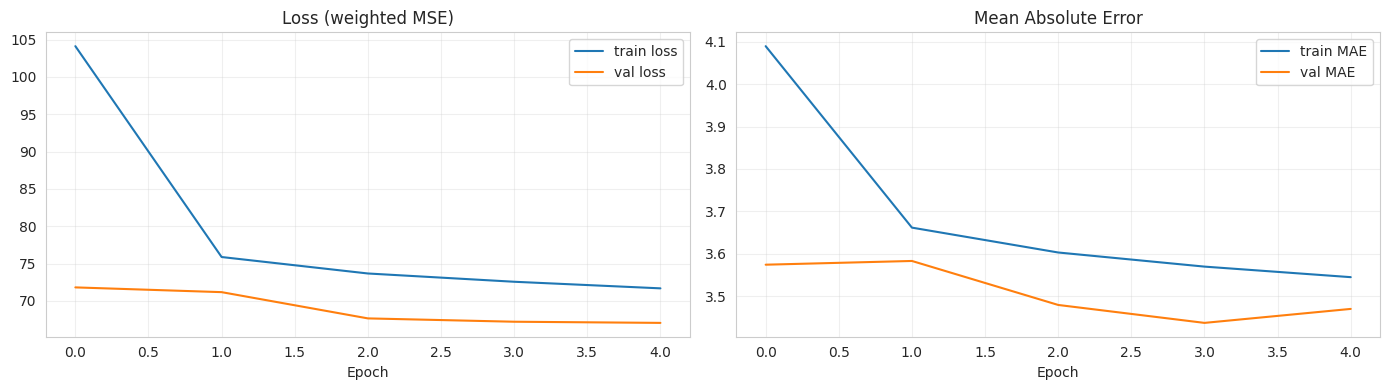

In [ ]:
hist = history.history

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(hist["loss"], label="train loss")
axes[0].plot(hist["val_loss"], label="val loss")
axes[0].set_title("Loss (weighted MSE)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist["mae"], label="train MAE")
axes[1].plot(hist["val_mae"], label="val MAE")
axes[1].set_title("Mean Absolute Error")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Quick Evaluation on Validation Set


In [ ]:
val_loss, val_mae = model.evaluate(X_val, y_val, verbose=0)
print(f"Val loss: {val_loss:.4f}  |  Val MAE: {val_mae:.4f}")

# Predict a small batch and compare
n_show = 5
preds = model.predict(X_val[:n_show], verbose=0)
print("\nSample predictions vs targets (pitch, step_norm, dur_norm):")
for i in range(n_show):
    print(f"  true: {np.round(y_val[i], 3)}  pred: {np.round(preds[i], 3)}")

Val loss: 67.0473  |  Val MAE: 3.4702

Sample predictions vs targets (pitch, step_norm, dur_norm):
  true: [ 7.10e+01 -6.90e-02 -4.57e-01]  pred: [ 7.7611e+01  7.0000e-02 -2.4900e-01]
  true: [88.    -0.468 -0.522]  pred: [73.363  0.092 -0.193]
  true: [74.    -0.522 -0.142]  pred: [ 6.5098e+01  1.3200e-01 -5.8000e-02]
  true: [52.    -0.234  0.903]  pred: [72.185  0.098 -0.166]
  true: [67.    -0.614 -0.452]  pred: [6.2814e+01 1.7700e-01 3.1000e-02]


## 9. Save Final Model + Training History

In [ ]:
model.save("models/lstm_final.keras")
print("Saved models/lstm_final.keras")

# Also keep best checkpoint path note
if os.path.exists("models/lstm_best.keras"):
    print("Best checkpoint: models/lstm_best.keras")

with open("models/train_history.pkl", "wb") as f:
    pickle.dump(hist, f)
print("Saved models/train_history.pkl")

# Save a small inference config (normalization stats needed for generation)
infer_config = {
    **config,
    "model_path": "models/lstm_best.keras",
}
with open("models/infer_config.pkl", "wb") as f:
    pickle.dump(infer_config, f)
print("Saved models/infer_config.pkl")

Saved models/lstm_final.keras
Best checkpoint: models/lstm_best.keras
Saved models/train_history.pkl
Saved models/infer_config.pkl


## 10. Summary

| Item | Value |
|------|--------|
| Architecture | 2× LSTM + Dense head |
| Input | `(batch, 32, 3)` note windows |
| Output | next `[pitch, step, duration]` |
| Loss | weighted MSE (pitch emphasized) |
| Artifacts | `models/lstm_best.keras`, `lstm_final.keras`, configs |

**Next notebook**: `04_generate.ipynb`  
→ Seed with a short sequence, sample many steps, write `.mid` files, listen.

---

**For contribution and insihght:** [S33mi](https://github.com/S33mi/)

Open to Data Science/Analytics and ML/ SI (fka AI) related opportunities